In [1]:
# Handle file and folder paths
from pathlib import Path

# Load and analyse tabular data
import pandas as pd

# Perform numerical operations
import numpy as np

# Create charts
import matplotlib.pyplot as plt

# Create statistical charts and set their style
import seaborn as sns

# Set a random seed for reproducible data splits later
RANDOM_STATE = 42

# Set the default chart style
sns.set_theme(style="whitegrid")

# Display all columns when previewing the dataset
pd.set_option("display.max_columns", None)

In [4]:
# Load fake news using the Python CSV parser
fake_df = pd.read_csv("Fake.csv", engine="python")

# Load real news using the Python CSV parser
true_df = pd.read_csv("True.csv", engine="python")

# Display dataset dimensions
print("Fake dataset shape:", fake_df.shape)
print("True dataset shape:", true_df.shape)

# Preview both datasets
display(fake_df.head())
display(true_df.head())

Fake dataset shape: (23481, 4)
True dataset shape: (21417, 4)


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [5]:
# Define the columns expected in both datasets
required_columns = {"title", "text", "subject", "date"}

# Check each dataset before continuing
for name, frame in [("Fake", fake_df), ("True", true_df)]:
    missing_columns = required_columns - set(frame.columns)  # Identify absent columns

    if missing_columns:
        raise ValueError(
            f"{name} dataset is missing columns: {missing_columns}"
        )  # Stop execution if required columns are missing

fake_df = fake_df.copy()              # Create a separate copy for labelling
true_df = true_df.copy()              # Create a separate copy for labelling

fake_df["label"] = 0                  # Assign 0 to fake news
true_df["label"] = 1                  # Assign 1 to real news

# Combine both datasets and create a continuous row index
df = pd.concat([fake_df, true_df], ignore_index=True)

print("Combined dataset shape:", df.shape)  # Display total rows and columns

print("\nClass counts:")
print(
    df["label"]
    .value_counts()                   # Count articles in each class
    .rename(index={0: "Fake", 1: "Real"})  # Display readable class names
)

display(df.head())                   # Preview the first five rows

Combined dataset shape: (44898, 5)

Class counts:
label
Fake    23481
Real    21417
Name: count, dtype: int64


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [6]:
print("COLUMN TYPES")
print(df.dtypes)                     # Check the data type of each column

print("\nMISSING VALUES")
print(df.isna().sum())                # Count missing values in each column

print("\nEXACT DUPLICATE ROWS")
print(df.duplicated().sum())          # Count rows identical across all columns

print("\nEMPTY OR WHITESPACE-ONLY TITLES")
print(
    df["title"]
    .fillna("")                      # Treat missing titles as empty for this check
    .astype(str)                     # Ensure values are strings
    .str.strip()                     # Remove surrounding whitespace
    .eq("")                          # Identify empty titles
    .sum()                           # Count them
)

print("\nEMPTY OR WHITESPACE-ONLY ARTICLE TEXT")
print(
    df["text"]
    .fillna("")                      # Treat missing articles as empty for this check
    .astype(str)                     # Ensure values are strings
    .str.strip()                     # Remove surrounding whitespace
    .eq("")                          # Identify empty articles
    .sum()                           # Count them
)

print("\nSUBJECT DISTRIBUTION BY CLASS")
display(
    pd.crosstab(
        df["subject"],               # Show subject categories as rows
        df["label"]                  # Show class labels as columns
    ).rename(columns={0: "Fake", 1: "Real"})  # Use readable column labels
)

COLUMN TYPES
title      object
text       object
subject    object
date       object
label       int64
dtype: object

MISSING VALUES
title      0
text       0
subject    0
date       0
label      0
dtype: int64

EXACT DUPLICATE ROWS
209

EMPTY OR WHITESPACE-ONLY TITLES
0

EMPTY OR WHITESPACE-ONLY ARTICLE TEXT
631

SUBJECT DISTRIBUTION BY CLASS


label,Fake,Real
subject,,
Government News,1570,0
Middle-east,778,0
News,9050,0
US_News,783,0
left-news,4459,0
politics,6841,0
politicsNews,0,11272
worldnews,0,10145


In [7]:
# Create a working copy of the combined dataset
clean_df = df.copy()

# Record the number of articles before cleaning
original_count = len(clean_df)

# Replace missing titles and article text with empty strings
clean_df["title"] = clean_df["title"].fillna("").astype(str)
clean_df["text"] = clean_df["text"].fillna("").astype(str)

# Remove whitespace from the beginning and end of text
clean_df["title"] = clean_df["title"].str.strip()
clean_df["text"] = clean_df["text"].str.strip()

# Identify articles without body text
empty_text = clean_df["text"].eq("")

# Display how many articles will be removed
print("Articles with empty body text:", empty_text.sum())

# Keep articles that contain body text
clean_df = clean_df.loc[~empty_text].copy()

# Report missing titles without removing otherwise usable articles
print("Remaining empty titles:", clean_df["title"].eq("").sum())
print("Articles remaining:", len(clean_df))

Articles with empty body text: 631
Remaining empty titles: 0
Articles remaining: 44267


In [8]:
# Create a normalised key for duplicate detection
# Preserve the original article text for later modelling
clean_df["text_key"] = (
    clean_df["text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Count repeated article bodies beyond their first occurrence
duplicate_count = clean_df.duplicated(subset="text_key").sum()

print("Repeated article bodies:", duplicate_count)

# Count the number of distinct labels assigned to each article body
labels_per_text = clean_df.groupby("text_key")["label"].nunique()

# Identify identical article bodies assigned to both classes
conflicting_keys = labels_per_text[labels_per_text > 1].index

# Identify all rows belonging to these conflicting groups
conflicting_rows = clean_df["text_key"].isin(conflicting_keys)

print("Article bodies with conflicting labels:", len(conflicting_keys))
print("Rows with conflicting labels:", conflicting_rows.sum())

# Preview conflicting examples if any exist
if conflicting_rows.any():
    display(
        clean_df.loc[
            conflicting_rows,
            ["title", "text", "label"]
        ].head(6)
    )

Repeated article bodies: 5630
Article bodies with conflicting labels: 0
Rows with conflicting labels: 0


In [9]:
# Remove all articles whose identical body text has conflicting labels
clean_df = clean_df.loc[~conflicting_rows].copy()

# Record the number of rows before removing remaining duplicates
before_deduplication = len(clean_df)

# Keep one copy of each normalised article body
clean_df = clean_df.drop_duplicates(
    subset="text_key",
    keep="first"
).copy()

# Reset the row index after cleaning
clean_df = clean_df.reset_index(drop=True)

# Display the cleaning summary
print(
    "Duplicate rows removed:",
    before_deduplication - len(clean_df)
)
print("Total rows removed:", original_count - len(clean_df))
print("Final dataset shape:", clean_df.shape)

# Display the remaining class counts
print("\nClass counts after cleaning:")
print(
    clean_df["label"]
    .value_counts()
    .rename(index={0: "Fake", 1: "Real"})
)

# Verify that no empty article bodies remain
assert clean_df["text"].str.strip().ne("").all()

# Verify that normalised article bodies are unique
assert clean_df["text_key"].is_unique

# Verify that both expected labels remain
assert set(clean_df["label"].unique()) == {0, 1}

print("\nBasic cleaning checks passed.")

Duplicate rows removed: 5630
Total rows removed: 6261
Final dataset shape: (38637, 6)

Class counts after cleaning:
label
Real    21189
Fake    17448
Name: count, dtype: int64

Basic cleaning checks passed.


In [10]:
# Import the function used to split the dataset
from sklearn.model_selection import train_test_split

# Split the data while preserving the proportion of both classes
train_df, test_df = train_test_split(
    clean_df,
    test_size=0.20,
    stratify=clean_df["label"],
    random_state=RANDOM_STATE
)

# Create independent copies and reset their row indices
train_df = train_df.copy().reset_index(drop=True)
test_df = test_df.copy().reset_index(drop=True)

# Display the size of each dataset
print("Training articles:", len(train_df))
print("Test articles:", len(test_df))

# Display class proportions to verify the stratified split
class_distribution = pd.DataFrame({
    "Training (%)": train_df["label"].value_counts(normalize=True) * 100,
    "Test (%)": test_df["label"].value_counts(normalize=True) * 100
})

# Replace numerical labels with readable names
class_distribution = class_distribution.rename(
    index={0: "Fake", 1: "Real"}
)

display(class_distribution.round(2))

Training articles: 30909
Test articles: 7728


,Training (%),Test (%)
label,,
Real,54.84,54.84
Fake,45.16,45.16


In [11]:
# Collect the normalised article bodies in each dataset
train_text_keys = set(train_df["text_key"])
test_text_keys = set(test_df["text_key"])

# Identify any matching article bodies across training and testing
overlapping_text = train_text_keys.intersection(test_text_keys)

print("Matching article bodies across the split:", len(overlapping_text))

# Stop execution if normalised exact duplicates overlap
assert len(overlapping_text) == 0, (
    "Duplicate article bodies were found across training and testing."
)

print("Normalised exact-duplicate overlap check passed.")

Matching article bodies across the split: 0
Normalised exact-duplicate overlap check passed.


In [12]:
# Select article body text as the initial model input
X_train = train_df["text"].copy()
X_test = test_df["text"].copy()

# Select the target labels
y_train = train_df["label"].copy()
y_test = test_df["label"].copy()

# Confirm that each article has a corresponding label
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

# Display the input dimensions
print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Test input shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Training input shape: (30909,)
Training target shape: (30909,)
Test input shape: (7728,)
Test target shape: (7728,)


In [13]:
# Create a separate copy for exploratory analysis
eda_df = train_df.copy()

# Create readable class names
eda_df["class_name"] = eda_df["label"].map({
    0: "Fake",
    1: "Real"
})

# Count whitespace-separated words in each article
eda_df["word_count"] = eda_df["text"].str.split().str.len()

# Count characters in each article
eda_df["character_count"] = eda_df["text"].str.len()

# Count whitespace-separated words in each title
eda_df["title_word_count"] = eda_df["title"].str.split().str.len()

# Display descriptive statistics for each class
display(
    eda_df.groupby("class_name")[
        ["word_count", "character_count", "title_word_count"]
    ].describe().round(2)
)

word_count                                                     \
                count    mean     std   min    25%    50%    75%     max   
class_name                                                                 
Fake          13958.0  426.92  358.72   1.0  279.0  377.0  504.0  8135.0   
Real          16951.0  385.48  274.83  22.0  148.0  359.0  522.0  5172.0   

           character_count                                                    \
                     count     mean      std    min      25%     50%     75%   
class_name                                                                     
Fake               13958.0  2557.99  2219.61    5.0  1661.25  2238.0  3006.0   
Real               16951.0  2381.19  1689.41  151.0   910.00  2218.0  3220.0   

                    title_word_count                                            
                max            count   mean   std  min   25%   50%   75%   max  
class_name                                                                      
Fake        51793.0          13958.0  14.31  3.96  1.0  12.0  14.0  16.0  42.0  
Real        29780.0          16951.0   9.95  1.69  4.0   9.0  10.0  11.0  20.0

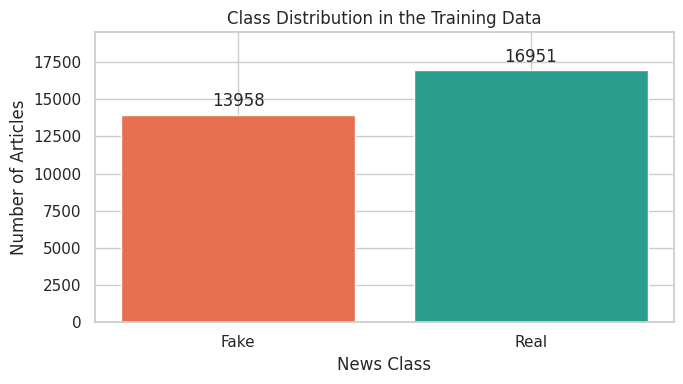

In [14]:
# Set a consistent class order and colour scheme
class_order = ["Fake", "Real"]
class_colours = ["#E76F51", "#2A9D8F"]

# Count articles in each class
class_counts = (
    eda_df["class_name"]
    .value_counts()
    .reindex(class_order)
)

# Create the class distribution chart
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=class_colours
)

# Display the article count above each bar
ax.bar_label(bars, fmt="%d", padding=3)

# Add chart labels
ax.set_title("Class Distribution in the Training Data")
ax.set_xlabel("News Class")
ax.set_ylabel("Number of Articles")

# Leave space above the bars for their labels
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

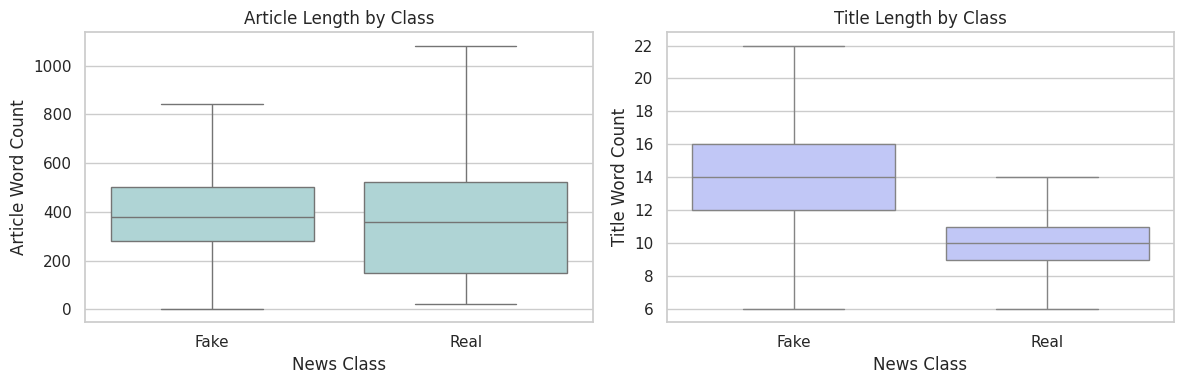

In [15]:
# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Compare article word counts across classes
sns.boxplot(
    data=eda_df,
    x="class_name",
    y="word_count",
    order=class_order,
    showfliers=False,
    color="#A8DADC",
    ax=axes[0]
)

axes[0].set_title("Article Length by Class")
axes[0].set_xlabel("News Class")
axes[0].set_ylabel("Article Word Count")

# Compare title word counts across classes
sns.boxplot(
    data=eda_df,
    x="class_name",
    y="title_word_count",
    order=class_order,
    showfliers=False,
    color="#B8C0FF",
    ax=axes[1]
)

axes[1].set_title("Title Length by Class")
axes[1].set_xlabel("News Class")
axes[1].set_ylabel("Title Word Count")

plt.tight_layout()
plt.show()

class_name,Fake,Real
subject,,
Government News,393,0
News,7303,0
US_News,621,0
left-news,547,0
politics,5094,0
politicsNews,0,9053
worldnews,0,7898


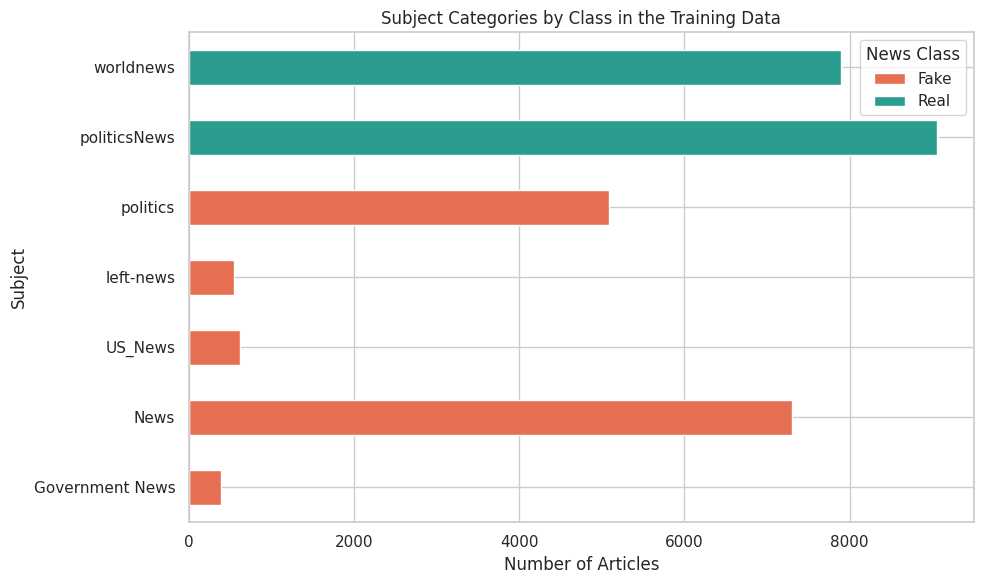

In [16]:
# Count articles by subject and class
subject_counts = pd.crosstab(
    eda_df["subject"].fillna("Missing"),
    eda_df["class_name"]
)

# Keep a consistent class order
subject_counts = subject_counts.reindex(
    columns=class_order,
    fill_value=0
)

# Display the counts
display(subject_counts)

# Plot the subject distribution
ax = subject_counts.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 6),
    color=class_colours
)

ax.set_title("Subject Categories by Class in the Training Data")
ax.set_xlabel("Number of Articles")
ax.set_ylabel("Subject")
ax.legend(title="News Class")

plt.tight_layout()
plt.show()

In [17]:
# Identify articles containing the word Reuters
eda_df["contains_reuters"] = eda_df["text"].str.contains(
    r"\breuters\b",
    case=False,
    regex=True,
    na=False
)

# Calculate the percentage containing Reuters within each class
reuters_summary = (
    eda_df.groupby("class_name")["contains_reuters"]
    .agg(["sum", "count", "mean"])
    .reindex(class_order)
)

# Rename the summary columns
reuters_summary.columns = [
    "Articles containing Reuters",
    "Total articles",
    "Proportion"
]

# Convert the proportion to a percentage
reuters_summary["Percentage"] = (
    reuters_summary["Proportion"] * 100
)

# Display the results
display(
    reuters_summary.drop(columns="Proportion").round(2)
)

,Articles containing Reuters,Total articles,Percentage
class_name,,,
Fake,176,13958,1.26
Real,16919,16951,99.81


In [19]:
# Import text feature extraction and pipeline tools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# Import classification models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Import cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_validate

In [20]:
# Use the same text feature settings for every model
tfidf_settings = {
    "lowercase": True,
    "ngram_range": (1, 2),
    "min_df": 3,
    "max_df": 0.95,
    "max_features": 10000,
    "sublinear_tf": True
}

# Create five reproducible folds that preserve class proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc"
}

In [23]:
# Import tools for out-of-fold predictions and evaluation
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, accuracy_score, f1_score

# Generate predictions for each training article using a model
# that was trained without that article's validation fold
lr_oof_predictions = cross_val_predict(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=1
)

# Print the classification report for both classes
print("LOGISTIC REGRESSION — CROSS-VALIDATION RESULTS")
print(
    classification_report(
        y_train,
        lr_oof_predictions,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        digits=4,
        zero_division=0
    )
)

# Print overall accuracy and macro F1
print(
    "Accuracy:",
    f"{accuracy_score(y_train, lr_oof_predictions):.4f}"
)
print(
    "Macro F1:",
    f"{f1_score(y_train, lr_oof_predictions, average='macro'):.4f}"
)

LOGISTIC REGRESSION — CROSS-VALIDATION RESULTS
              precision    recall  f1-score   support

        Fake     0.9931    0.9838    0.9884     13958
        Real     0.9868    0.9944    0.9906     16951

    accuracy                         0.9896     30909
   macro avg     0.9899    0.9891    0.9895     30909
weighted avg     0.9896    0.9896    0.9896     30909

Accuracy: 0.9896
Macro F1: 0.9895


In [24]:
# Generate out-of-fold predictions using the Naive Bayes pipeline
nb_oof_predictions = cross_val_predict(
    nb_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=1
)

# Print the classification report for both classes
print("MULTINOMIAL NAIVE BAYES — CROSS-VALIDATION RESULTS")
print(
    classification_report(
        y_train,
        nb_oof_predictions,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        digits=4,
        zero_division=0
    )
)

# Print overall accuracy and macro F1
print(
    "Accuracy:",
    f"{accuracy_score(y_train, nb_oof_predictions):.4f}"
)
print(
    "Macro F1:",
    f"{f1_score(y_train, nb_oof_predictions, average='macro'):.4f}"
)

MULTINOMIAL NAIVE BAYES — CROSS-VALIDATION RESULTS
              precision    recall  f1-score   support

        Fake     0.9546    0.9465    0.9505     13958
        Real     0.9562    0.9629    0.9596     16951

    accuracy                         0.9555     30909
   macro avg     0.9554    0.9547    0.9550     30909
weighted avg     0.9555    0.9555    0.9555     30909

Accuracy: 0.9555
Macro F1: 0.9550


In [29]:
# Import modelling tools
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report
from xgboost import XGBClassifier

# Create a lightweight text classification pipeline
xgb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=3000,
        min_df=3,
        lowercase=True
    )),
    ("model", XGBClassifier(
        n_estimators=50,
        max_depth=3,
        learning_rate=0.1,
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    ))
])

# Use three folds to reduce computation
xgb_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Generate validation predictions using only the training data
xgb_oof_predictions = cross_val_predict(
    xgb_pipeline,
    X_train,
    y_train,
    cv=xgb_cv,
    method="predict",
    n_jobs=1
)

# Print the classification report
print(" XGBOOST RESULTS")
print(
    classification_report(
        y_train,
        xgb_oof_predictions,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        digits=4,
        zero_division=0
    )
)

 XGBOOST RESULTS
              precision    recall  f1-score   support

        Fake     0.9976    0.9929    0.9953     13958
        Real     0.9942    0.9981    0.9961     16951

    accuracy                         0.9957     30909
   macro avg     0.9959    0.9955    0.9957     30909
weighted avg     0.9957    0.9957    0.9957     30909



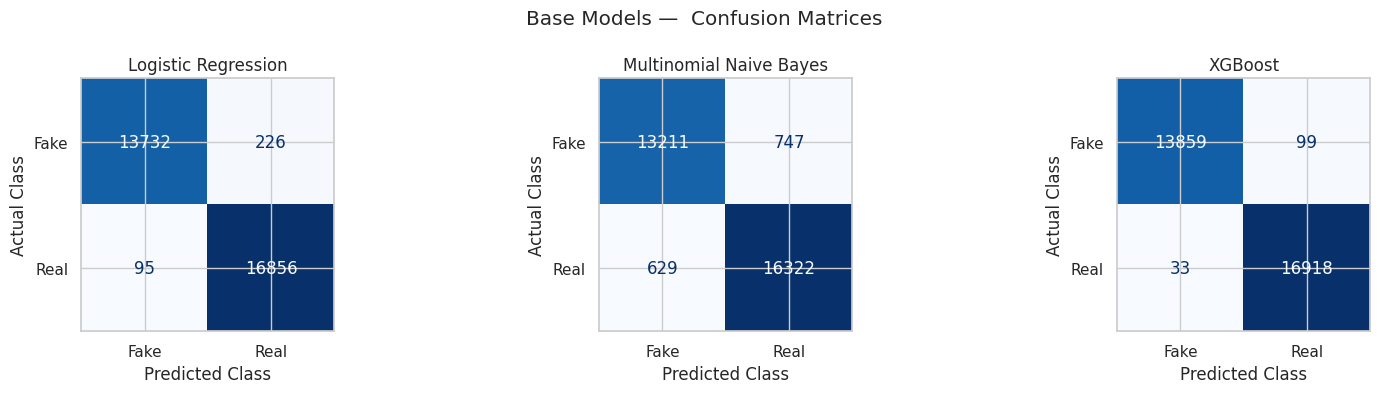

In [31]:
# Import plotting and evaluation tools
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Store the existing validation predictions for each model
model_predictions = {
    "Logistic Regression": lr_oof_predictions,
    "Multinomial Naive Bayes": nb_oof_predictions,
    "XGBoost": xgb_oof_predictions
}

# Create one plot for each model
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Plot each model's confusion matrix
for ax, (model_name, predictions) in zip(
    axes, model_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_train,
        predictions,
        labels=[0, 1],
        display_labels=["Fake", "Real"],
        cmap="Blues",
        colorbar=False,
        values_format="d",
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle("Base Models —  Confusion Matrices")
plt.tight_layout()
plt.show()

Generating probabilities: Logistic Regression
Generating probabilities: Multinomial Naive Bayes
Generating probabilities: XGBoost


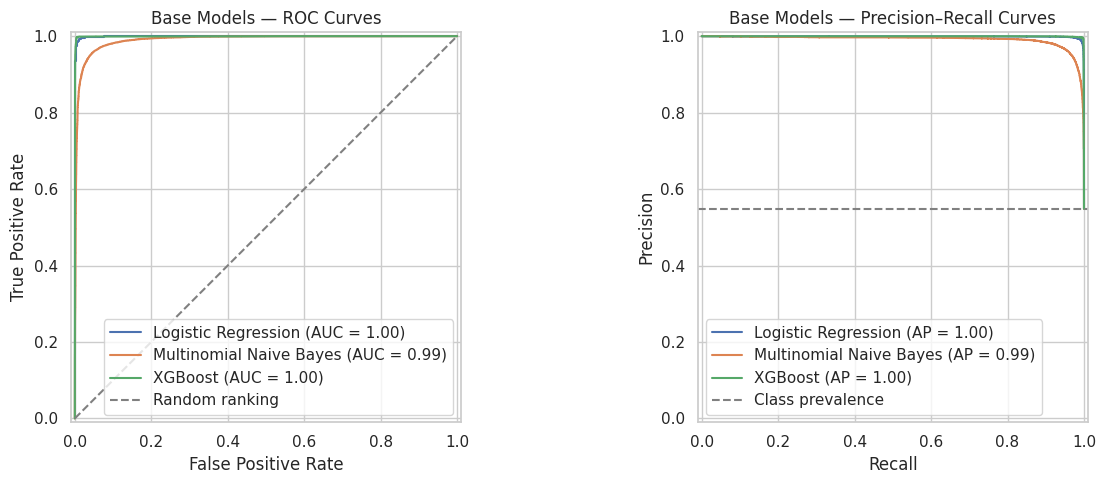

In [32]:
# Import plotting and evaluation tools
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Use the same validation folds for all three models
plot_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Store the existing base model pipelines
base_models = {
    "Logistic Regression": lr_pipeline,
    "Multinomial Naive Bayes": nb_pipeline,
    "XGBoost": xgb_pipeline
}

# Store validation probabilities for reuse
base_oof_probabilities = {}

# Generate probabilities using only the training dataset
for model_name, model in base_models.items():

    print("Generating probabilities:", model_name)

    probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=plot_cv,
        method="predict_proba",
        n_jobs=1
    )

    # Select the probability of class 1, which represents real news
    base_oof_probabilities[model_name] = probabilities[:, 1]

# Create two evaluation plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot ROC curves for all three models
for model_name, probabilities in base_oof_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_train,
        probabilities,
        name=model_name,
        ax=axes[0]
    )

# Add the random-ranking reference line
axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random ranking"
)

axes[0].set_title("Base Models — ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# Plot precision–recall curves for all three models
for model_name, probabilities in base_oof_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_train,
        probabilities,
        name=model_name,
        ax=axes[1]
    )

# Add the positive-class prevalence as a reference
axes[1].axhline(
    y=y_train.mean(),
    linestyle="--",
    color="grey",
    label="Class prevalence"
)

axes[1].set_title("Base Models — Precision–Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

In [33]:
# Import the hyperparameter search tool
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Use the same folds for all three models
tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [34]:
# Define the regularisation strengths to compare
lr_parameters = {
    "model__C": [0.1, 1.0, 10.0]
}

# Set up the search using macro F1
lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_parameters,
    scoring="f1_macro",
    cv=tuning_cv,
    n_jobs=1,
    refit=True,
    error_score="raise"
)

# Tune using only the training data
lr_search.fit(X_train, y_train)

# Store the best pipeline refitted on the complete training data
lr_tuned = lr_search.best_estimator_

# Display the selected settings and validation score
print("LOGISTIC REGRESSION")
print("Best parameters:", lr_search.best_params_)
print("Best CV Macro F1:", f"{lr_search.best_score_:.4f}")

LOGISTIC REGRESSION
Best parameters: {'model__C': 10.0}
Best CV Macro F1: 0.9939


In [35]:
# Define smoothing strengths to compare
nb_parameters = {
    "model__alpha": [0.1, 0.5, 1.0, 2.0]
}

# Set up the search using the same folds and metric
nb_search = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=nb_parameters,
    scoring="f1_macro",
    cv=tuning_cv,
    n_jobs=1,
    refit=True,
    error_score="raise"
)

# Tune using only the training data
nb_search.fit(X_train, y_train)

# Store the best pipeline refitted on the complete training data
nb_tuned = nb_search.best_estimator_

# Display the selected settings and validation score
print("MULTINOMIAL NAIVE BAYES")
print("Best parameters:", nb_search.best_params_)
print("Best CV Macro F1:", f"{nb_search.best_score_:.4f}")

MULTINOMIAL NAIVE BAYES
Best parameters: {'model__alpha': 0.1}
Best CV Macro F1: 0.9578


In [36]:
# Compare tree counts and depths while keeping the learning rate fixed
xgb_parameters = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [2, 3],
    "model__learning_rate": [0.1]
}

# Run folds sequentially to limit CPU and memory use
xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_parameters,
    scoring="f1_macro",
    cv=tuning_cv,
    n_jobs=1,
    refit=True,
    error_score="raise"
)

# Tune using only the training data
xgb_search.fit(X_train, y_train)

# Store the best pipeline refitted on the complete training data
xgb_tuned = xgb_search.best_estimator_

# Display the selected settings and validation score
print("XGBOOST")
print("Best parameters:", xgb_search.best_params_)
print("Best CV Macro F1:", f"{xgb_search.best_score_:.4f}")

XGBOOST
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}
Best CV Macro F1: 0.9962


In [37]:
# Import pandas for the comparison table
import pandas as pd

# Collect the selected parameters and cross-validation scores
tuning_summary = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Best Parameters": lr_search.best_params_,
        "Best CV Macro F1": lr_search.best_score_
    },
    {
        "Model": "Multinomial Naive Bayes",
        "Best Parameters": nb_search.best_params_,
        "Best CV Macro F1": nb_search.best_score_
    },
    {
        "Model": "XGBoost",
        "Best Parameters": xgb_search.best_params_,
        "Best CV Macro F1": xgb_search.best_score_
    }
])

# Rank the models by the tuning selection metric
tuning_summary = tuning_summary.sort_values(
    "Best CV Macro F1",
    ascending=False
).reset_index(drop=True)

display(tuning_summary)

,Model,Best Parameters,Best CV Macro F1
0,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.996178
1,Logistic Regression,{'model__C': 10.0},0.993922
2,Multinomial Naive Bayes,{'model__alpha': 0.1},0.957767


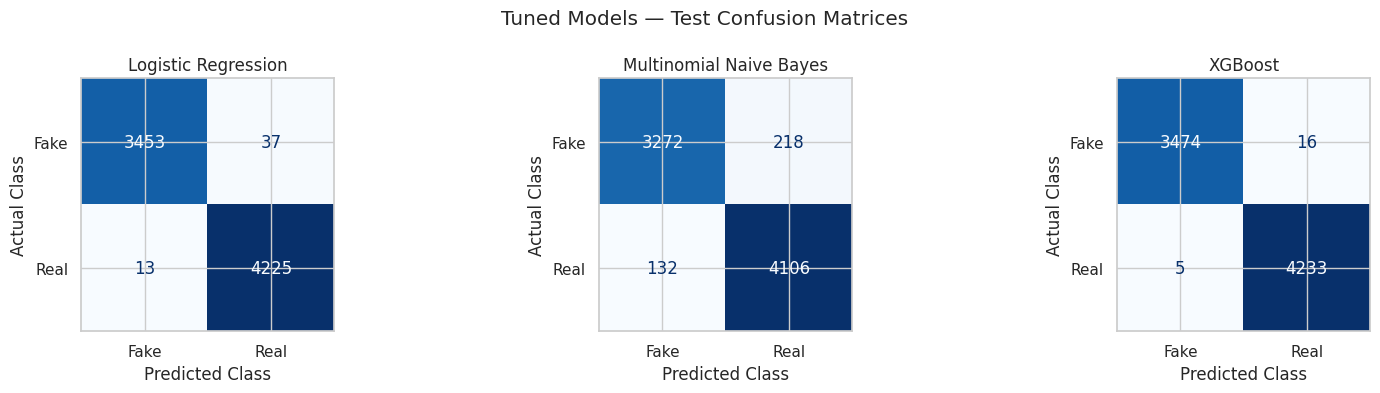

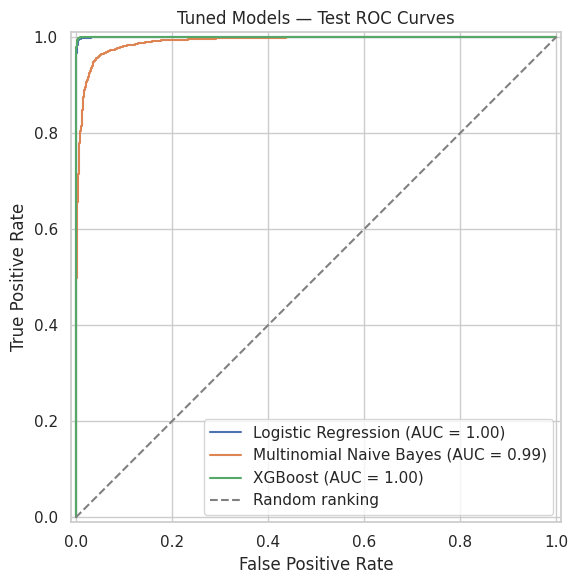

TEST ROC-AUC SCORES
Logistic Regression: 0.999697
Multinomial Naive Bayes: 0.989838
XGBoost: 0.999897


In [38]:
# Import plotting and evaluation tools
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)

# Store the tuned pipelines fitted on the training data
tuned_models = {
    "Logistic Regression": lr_tuned,
    "Multinomial Naive Bayes": nb_tuned,
    "XGBoost": xgb_tuned
}

# Store test predictions and probabilities for later analysis
tuned_test_predictions = {}
tuned_test_probabilities = {}

# Generate predictions without fitting models on the test data
for model_name, model in tuned_models.items():

    tuned_test_predictions[model_name] = model.predict(X_test)

    # Locate the probability column for real news
    positive_class_index = list(model.classes_).index(1)

    tuned_test_probabilities[model_name] = model.predict_proba(
        X_test
    )[:, positive_class_index]

# Create a confusion matrix for each tuned model
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, model_name in zip(axes, tuned_models):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        tuned_test_predictions[model_name],
        labels=[0, 1],
        display_labels=["Fake", "Real"],
        cmap="Blues",
        colorbar=False,
        values_format="d",
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

fig.suptitle("Tuned Models — Test Confusion Matrices")
plt.tight_layout()
plt.show()

# Plot all tuned model ROC curves together
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, probabilities in tuned_test_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=ax
    )

# Add the random-ranking reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random ranking"
)

ax.set_title("Tuned Models — Test ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

# Print AUC values with enough precision to inspect near-perfect results
print("TEST ROC-AUC SCORES")

for model_name, probabilities in tuned_test_probabilities.items():
    auc = roc_auc_score(y_test, probabilities)
    print(f"{model_name}: {auc:.6f}")

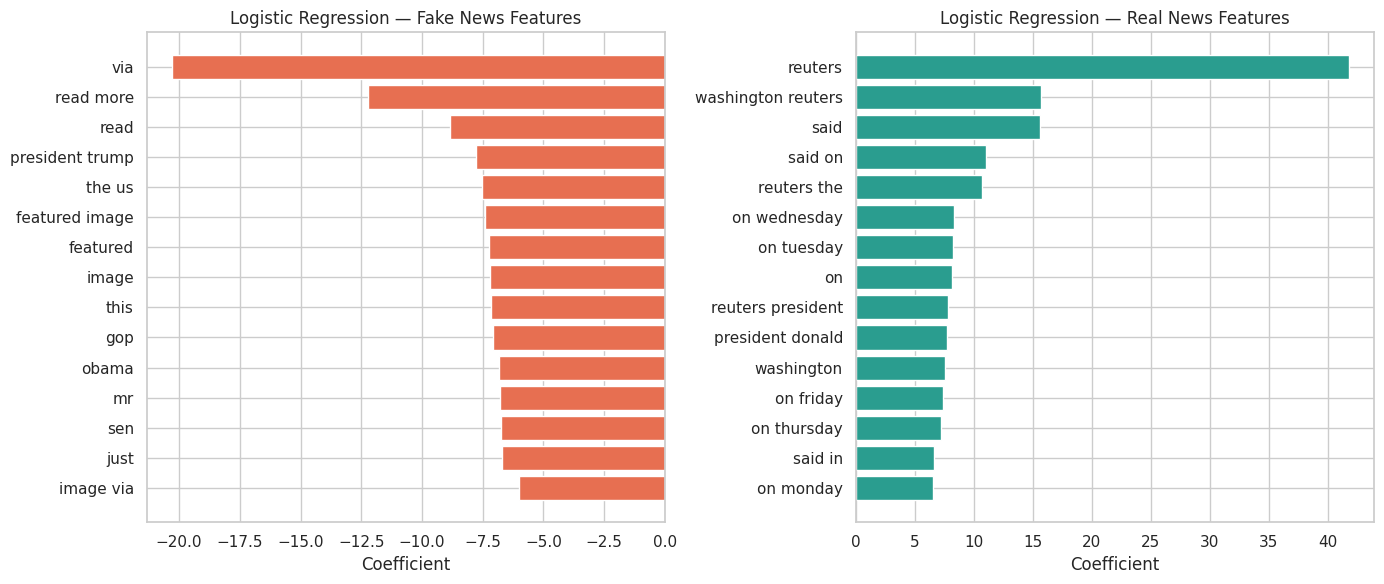

In [39]:
# Import numerical and plotting tools
import numpy as np
import matplotlib.pyplot as plt

# Extract feature names and model coefficients
lr_features = lr_tuned.named_steps["tfidf"].get_feature_names_out()
lr_coefficients = lr_tuned.named_steps["model"].coef_[0]

# Select the strongest coefficients in each direction
fake_indices = np.argsort(lr_coefficients)[:15]
real_indices = np.argsort(lr_coefficients)[-15:]

# Create separate plots for each class
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot features associated with fake news
axes[0].barh(
    lr_features[fake_indices],
    lr_coefficients[fake_indices],
    color="#E76F51"
)
axes[0].invert_yaxis()
axes[0].set_title("Logistic Regression — Fake News Features")
axes[0].set_xlabel("Coefficient")

# Plot features associated with real news
axes[1].barh(
    lr_features[real_indices],
    lr_coefficients[real_indices],
    color="#2A9D8F"
)
axes[1].set_title("Logistic Regression — Real News Features")
axes[1].set_xlabel("Coefficient")

plt.tight_layout()
plt.show()